#  Dense Neural Network DNN – Case Study: Chatter
 Deep Learning for Sequential Process Data

 In this notebook, you will practice using TensorFlow with dense layers, applying them to the phenomenon known as "chatter."

During the manufacturing of components, disruptive vibrations—referred to as "chatter"—can occur. This damages tools and results in lower component quality.

The "Chatter" dataset contains measurements of spindle speed and depth of cut from a CNC milling machine. The objective is to create a model (in this case, a neural network) capable of predicting the combinations of spindle speed and depth of cut that lead to chatter.

In [2]:
import numpy as np
import ml_dtypes
import tensorflow as tf

print("NumPy:", np.__version__)
print("ml-dtypes:", ml_dtypes.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 1.26.4
ml-dtypes: 0.3.2
TensorFlow: 2.16.1


1\. Importing libraries

In [4]:
''' Import of the most important packages. '''
import numpy as np
import pandas as pd
import random
import os

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import seaborn as sns

#Settings for graphics output
style = 'seaborn-v0_8-whitegrid'
plt.style.use(style)
plt.rcParams.update({'font.size': 14})  # Font size of all text characters in the graph


In [5]:
''' Check whether TensorFlow is installed and whether it is using the GPU or the CPU. '''
print('TF version: ' + tf.__version__)
if tf.test.is_built_with_gpu_support():
    if len(tf.config.list_physical_devices('GPU'))==0:
         print('Attention: TensorFlow is currently using the CPU, not the GPU!')
    else:
        print('Default GPU Device: {}'.format(tf.config.list_physical_devices('GPU')))
        # GPU-Memory-Management:
        config = tf.compat.v1.ConfigProto()
        config.gpu_options.allow_growth = True
        session = tf.compat.v1.Session(config=config)
else:
    print('TensorFlow CPU version active')

TF version: 2.16.1
TensorFlow CPU version active



* Choose a number between 1 and 100 to generate your specific random numbers (my_seed)

To ensure that results are reproducible, several seeds must be set for the random number generators.

In [45]:
''' Setting seeds to enable reproducibility. '''
# The seed number can be changed with every new run of notebook 
my_seed = random.randint(1, 100)

# Ausgabe gewählte Zufallszahlen
print("\nNumber chosen for random number generation: \t" + str(my_seed))

# Set seeds for various random number generators
os.environ['PYTHONHASHSEED']=str(my_seed)
tf.random.set_seed(my_seed)
random.seed(my_seed)
np.random.seed(my_seed)


Number chosen for random number generation: 	95


 to fix the seed number it is recommend t give it at the beginning of notebook 

In [46]:
# to fix the seed number it is recommend t give it at the beginning of notebook 
my_seed = 42

os.environ['PYTHONHASHSEED'] = str(my_seed)
tf.random.set_seed(my_seed)
random.seed(my_seed)
np.random.seed(my_seed)

2\. Collect data

In [47]:
""" Load data using pandas. """
df_train = pd.read_csv("Trainingdata_Chatter.csv")
df_test = pd.read_csv("Testdata_Chatter.csv")
print('Data successfully imported')

Data successfully imported


In [48]:
## 2. Exploring data

In [49]:
""" First rows of the training dataset as an example. """
df_train.head(5)

,Spindle speed,depth of cut,chatter
0,8052.714883,0.005008,0
1,14609.266695,0.013545,0
2,10958.025235,0.016669,0
3,14826.239580,0.005246,1
4,8269.823433,0.009468,0


In [50]:
""" Statistical description of the training data set. """
df_train.describe()

,Spindle speed,depth of cut,chatter
count,1000.000000,1000.000000,1000.000000
mean,11914.715950,0.011585,0.312000
std,2318.877498,0.006086,0.463542
min,8002.157250,0.001039,0.000000
25%,9896.591517,0.006148,0.000000
50%,11867.341154,0.011705,0.000000
75%,13946.390335,0.016934,1.000000
max,15965.799516,0.021996,1.000000


In [51]:
df_train.columns

Index(['Spindle speed', ' depth of cut', ' chatter'], dtype='object')

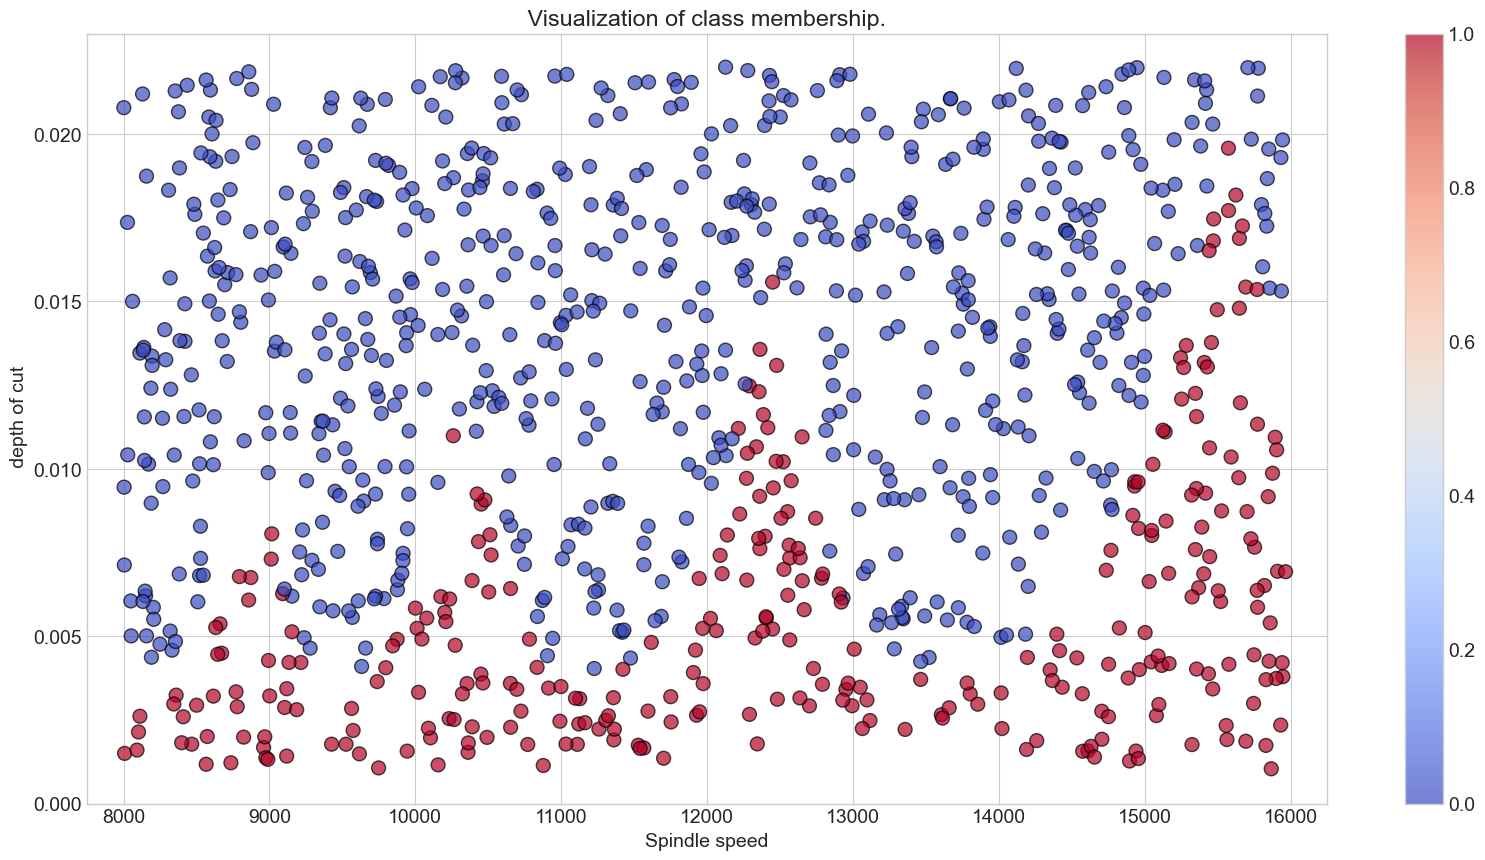

In [52]:
""" Visualization of class membership. """
fig = plt.figure(figsize=(20, 10))
surf = plt.scatter(df_train["Spindle speed"],
                   df_train[" depth of cut"],
                   c=df_train[" chatter"],
                   cmap=plt.cm.coolwarm,
                   s=100,
                   alpha=0.7,
                   edgecolors="black")

plt.colorbar(surf)
plt.xlim(7750, 16250)
plt.ylim(0, 0.023)
plt.xlabel("Spindle speed")
plt.ylabel(" depth of cut")
plt.title(""" Visualization of class membership. """)
plt.show()

3\. Preparing Data

In [53]:
""" Splitting into X and y. """
X_train = df_train.drop(columns=[' chatter']).to_numpy()
y_train = df_train[' chatter'].to_numpy(dtype='int32')

X_test = df_test.drop(columns=[' chatter']).to_numpy()
y_test = df_test[' chatter'].to_numpy(dtype='int32')


In [54]:
""" Splitting into X and y. """
# Defining the proportion of validation data
validation_split = 0.15

# Splitting the data
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=validation_split, shuffle=True, random_state=my_seed)

# Outputting the number of samples per dataset
nr_train = len(X_train)
nr_val = len(X_val)
nr_test = len(X_test)
print(nr_train, "training sequences")
print(nr_val, "validation sequences")
print(nr_test, "test sequences")

850 training sequences
150 validation sequences
200 test sequences


In [55]:
""" Normalize the data. """
# Import and fit the scaler (i.e., the scaler learns the mean values ​​and standard deviations of the features)
scaler = StandardScaler().fit(X_train)

# Normalize the data using the learned parameters and format it accordingly
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)
print('Data preparation complete')

Data preparation complete


In [36]:
''' Checking the shape of the Numpy arrays. '''
print('Shape X_train: ' + str(X_train.shape))
print('Shape X_val: ' + str(X_val.shape))
print('Shape X_test: ' + str(X_test.shape))

Shape X_train: (850, 2)
Shape X_val: (150, 2)
Shape X_test: (200, 2)


4\. Building Models



* First, the model structure must be defined.
* You are free to decide on the number of layers and the number of nodes per layer.
* Experiment with different model sizes to find the best model for the task.

Useful links:
* https://keras.io/guides/sequential_model/
* https://keras.io/api/layers/core_layers/dense/  

In [56]:
''' Model Construction '''
# Import the necessary classes and functions
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Determine the shape of a single training example
input_shape = (2,) # The input to the model is a 1D tensor of length 2

# Define the model
model = Sequential()
# Add Dense layers
model.add(Dense(64, activation='relu', input_shape=input_shape))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='sigmoid')) # Output layer for binary classification

model.summary()

C:\Users\Dr.KN\anaconda3\envs\tensorflow\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                      │ (None, 64)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,305 (9.00 KB)

 Trainable params: 2,305 (9.00 KB)

 Non-trainable params: 0 (0.00 B)

4\.1 Model Compilation

The optimizer, the loss function, and the metric have already been defined.

In [57]:
''' Compile the model. '''
# Define the optimizer
optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3)

# Configure the model for subsequent training
model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=['acc'])


4\.2 Model Training


* Select the number of epochs for which the model should be trained.
* Then, define the training inputs, training outputs, and validation data.

Output:
* Intermediate results for each epoch

In [58]:
''' Train the model '''
# Define the batch size and number of epochs
batch_size = 32
epochs = 50 # You can adjust the number of epochs
# Perform the training. The results for each epoch are stored in the history object.
history = model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs,
validation_data=(X_val, y_val), shuffle=True)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - acc: 0.7788 - loss: 0.5920 - val_acc: 0.8133 - val_loss: 0.5249
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - acc: 0.8341 - loss: 0.4419 - val_acc: 0.8267 - val_loss: 0.4058
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - acc: 0.8447 - loss: 0.3635 - val_acc: 0.8200 - val_loss: 0.3454
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - acc: 0.8541 - loss: 0.3335 - val_acc: 0.8200 - val_loss: 0.3236
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - acc: 0.8635 - loss: 0.3212 - val_acc: 0.8200 - val_loss: 0.3133
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - acc: 0.8647 - loss: 0.3135 - val_acc: 0.8267 - val_loss: 0.3061
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - acc: 0.8624 - loss: 0.3075 - val_acc: 0.8267 - val_loss: 0.3004
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.8659 - loss: 0.3027 - val_acc: 0.8333 - val_loss: 0.2957
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - acc: 0.8671 - loss:

4\.3 Validating model

Metrics for training and validation:

In [59]:
print('Metrics (loss and accuracy) for training:')
print(model.evaluate(X_train, y_train))
print('Metrics (loss and accuracy) for validation:')
print(model.evaluate(X_val, y_val))

Metrics (loss and accuracy) for training:
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.9012 - loss: 0.2186
[0.21858642995357513, 0.9011764526367188]
Metrics (loss and accuracy) for validation:
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - acc: 0.8800 - loss: 0.2263 
[0.22630982100963593, 0.8799999952316284]


 Visualization of the Training Progress

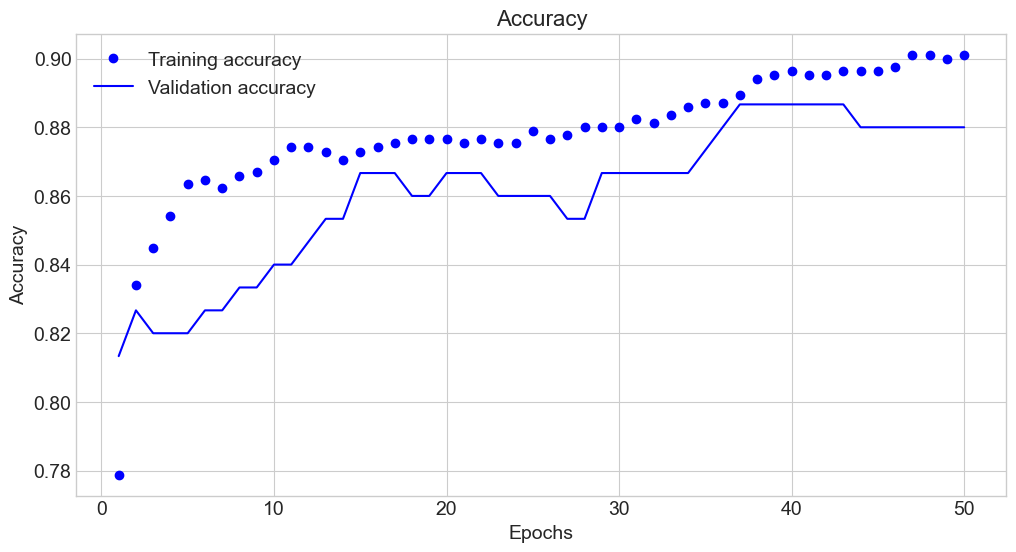

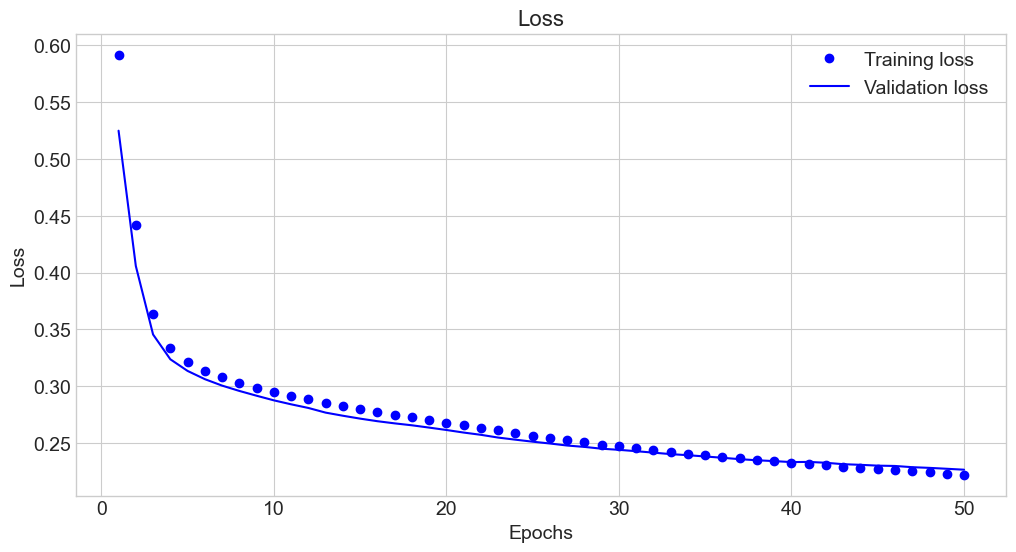

In [60]:
""" Plot training history. """
train_acc = history.history['acc']
val_acc = history.history['val_acc']
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1,len(train_acc) +1)

plt.figure(figsize=(12,6))
plt.plot(epochs, train_acc,'bo', label='Training accuracy')
plt.plot(epochs, val_acc,'b', label='Validation accuracy')

plt.title('Accuracy', fontsize=16)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.legend()

plt.figure(figsize=(12,6))
plt.plot(epochs, train_loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')

plt.title('Loss', fontsize = 16)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.legend()
plt.show()

5\. Testing & Applying the Model

Only proceed to this step once you are satisfied with your model.

The purpose of testing a model is to determine how well it can be transferred and generalized.
If you test all your models, you might end up selecting the one that fits the test dataset best—rather than the one that actually provides the best overall solution to the problem. In doing so, you are effectively overfitting to the test dataset.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Results for the test set:
Accuracy: 	0.865
F1-Score: 	0.8029


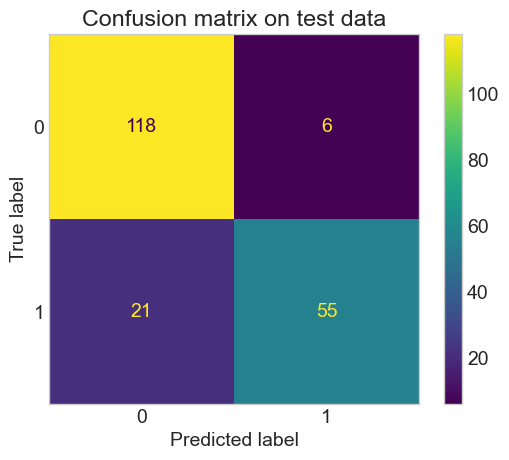

Classification Report
              precision    recall  f1-score   support

           0       0.85      0.95      0.90       124
           1       0.90      0.72      0.80        76

    accuracy                           0.86       200
   macro avg       0.88      0.84      0.85       200
weighted avg       0.87      0.86      0.86       200



In [61]:
"""Evaluate model using test data"""
y_test_pred = (model.predict(X_test)>0.5).astype("int32")
# Calculate accuracy on the test data
accuracy_test = accuracy_score(y_test, y_test_pred)

# Calculate the F1-score on the test data
f1score_test = f1_score(y_test, y_test_pred)

# Output the model accuracy
print('Results for the test set:')
print('Accuracy: \t' + str(round(accuracy_test, 4)))
print('F1-Score: \t' + str(round(f1score_test, 4)))

# Visualization of the confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.grid()
plt.title('Confusion matrix on test data')
plt.show()

# Classification report
print('Classification Report')
print(classification_report(y_test, y_test_pred))

6\. Visualizing model predictions

Since the model requires only two input parameters, we can graphically visualize all possible model predictions.

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


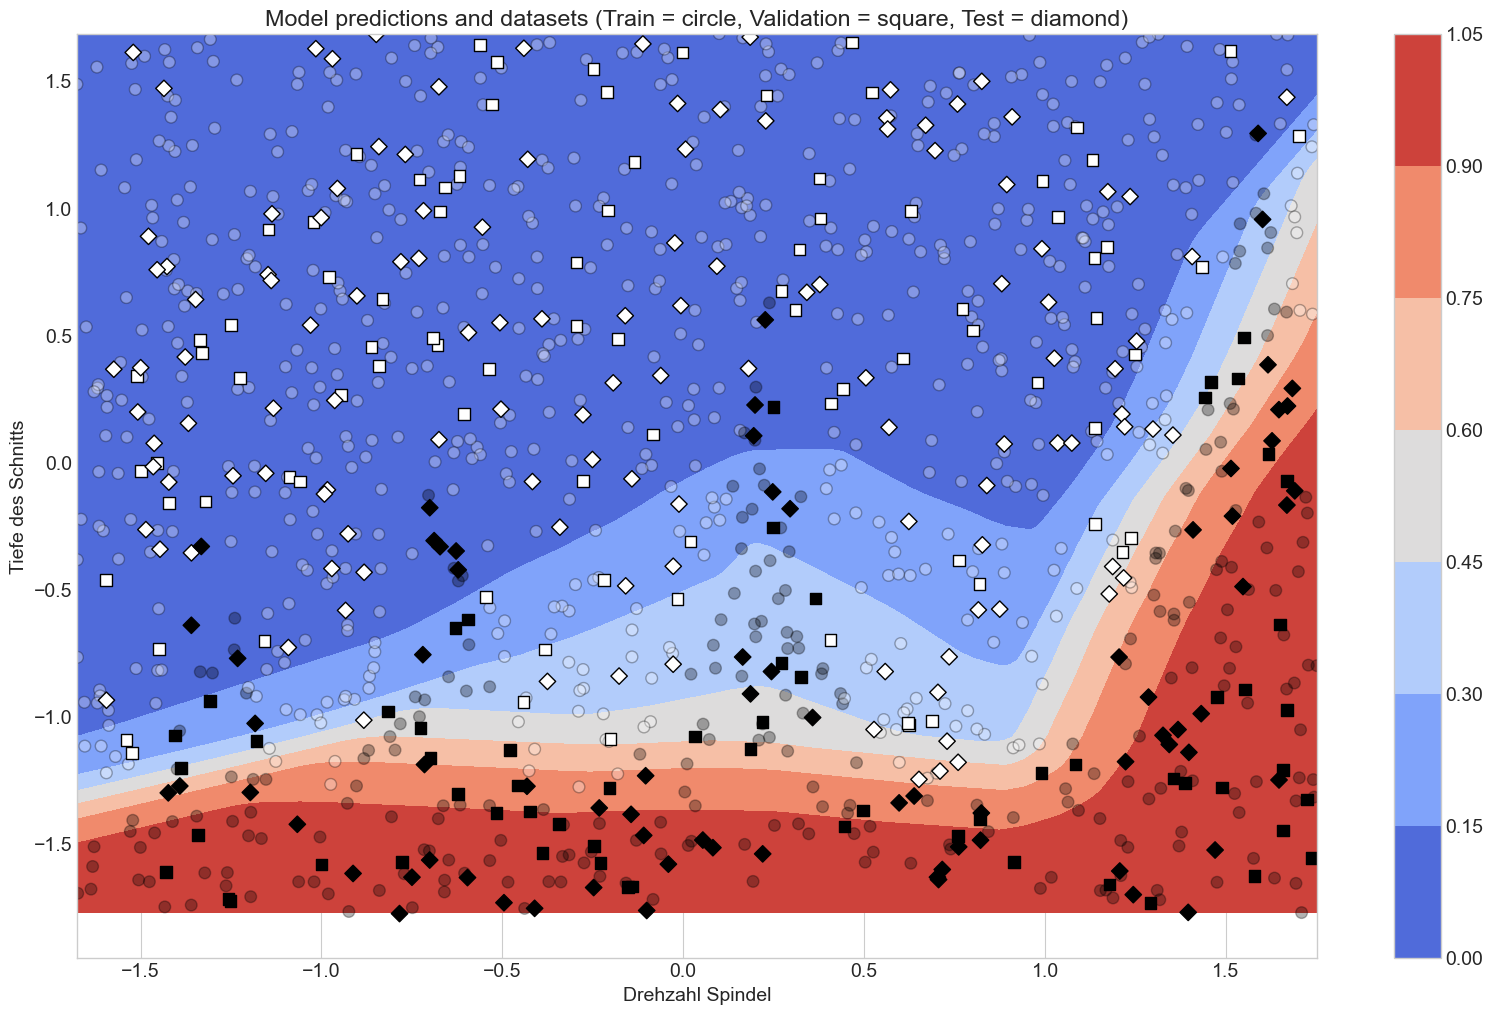

In [62]:
''' Visualization of model predictions and decision boundary. '''
# Create a grid for model output
x = np.linspace(
X_train[:, 0].min(), X_train[:, 0].max(), 200
)
y = np.linspace(
X_train[:, 1].min(), X_train[:, 1].max(), 200
)
X, Y = np.meshgrid(x, y)

# Calculate model predictions
z = pd.DataFrame({"Drehzahl Spindel": X.ravel(), "Tiefe des Schnitts": Y.ravel()})
z = model.predict(z)

# Plot model predictions

Z = np.asarray(z).reshape(200, 200)
fig = plt.figure(figsize=(20, 12))
plt.title("Model predictions and datasets (Train = circle, Validation = square, Test = diamond)")
plt.xlabel("Drehzahl Spindel")
plt.ylabel("Tiefe des Schnitts")
surf = plt.contourf(X, Y, Z, cmap=plt.cm.coolwarm)
plt.colorbar(surf)
plt.scatter(
X_train[:, 0],
X_train[:, 1],
c=y_train,
marker="o",
alpha=0.3,
edgecolors="black",
s=70)
plt.scatter(
X_val[:, 0],
X_val[:, 1],
c=y_val,
marker="s",
edgecolors="black",
s=70)
plt.scatter(
X_test[:, 0],
X_test[:, 1],
c=y_test,
marker="D",
edgecolors="black",
s=70)
plt.show()

7\.   Defining a model using the Functional API

The Functional API is useful for more complex model architectures.

https://keras.io/guides/functional_api/

In [63]:
"""Functional Model"""

inputs = keras.Input(shape=input_shape, dtype="float32")
x = Dense(64, activation='relu')(inputs)
x = Dense(32, activation='relu')(x)
outputs = Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 2)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 64)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,305 (9.00 KB)

 Trainable params: 2,305 (9.00 KB)

 Non-trainable params: 0 (0.00 B)

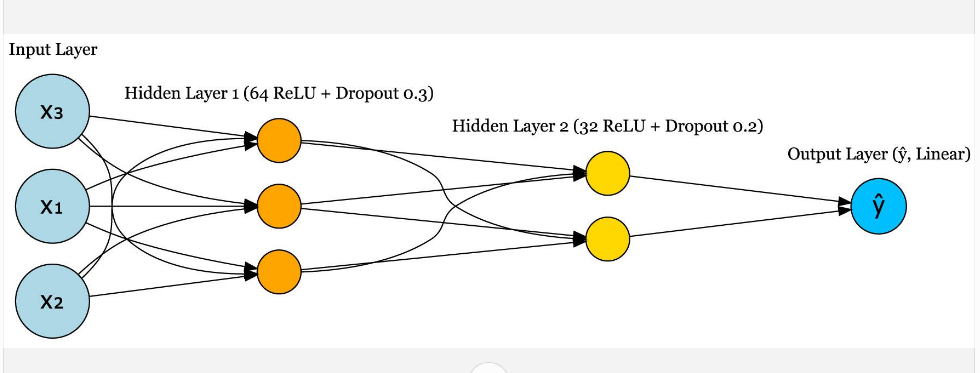


Parameters = (N_inputs+1)N_neurons


Module Compiling 

In [64]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

 Module Training 

In [67]:

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8706 - loss: 0.2692 - val_accuracy: 0.8600 - val_loss: 0.2636
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8718 - loss: 0.2666 - val_accuracy: 0.8533 - val_loss: 0.2614
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8741 - loss: 0.2640 - val_accuracy: 0.8600 - val_loss: 0.2590
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8765 - loss: 0.2614 - val_accuracy: 0.8600 - val_loss: 0.2570
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8753 - loss: 0.2588 - val_accuracy: 0.8600 - val_loss: 0.2549
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8788 - loss: 0.2561 - val_accuracy: 0.8600 - val_loss: 0.2527
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8788 - loss: 0.2534 - val_accuracy: 0.8667 - val_loss: 0.2512
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8788 - loss: 0.2506 - val_accuracy: 0.8733 - val_los

In [68]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Предсказания Functional API
y_pred_functional = (model.predict(X_test) >= 0.5).astype(int)

# Метрики
print("Accuracy:", accuracy_score(y_test, y_pred_functional))
print("Precision:", precision_score(y_test, y_pred_functional))
print("Recall:", recall_score(y_test, y_pred_functional))
print("F1:", f1_score(y_test, y_pred_functional))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Accuracy: 0.915
Precision: 0.9682539682539683
Recall: 0.8026315789473685
F1: 0.8776978417266187
